In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)

    import numpy as np
    import pandas as pd
    import scanpy as sc

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
adata = sc.read_h5ad("../adata_all_harm_ribo.h5ad")
# contains raw
obs = pd.read_csv(
    ".././0_adata obs - reduced and filt.csv",
    index_col=0,
)
adata = adata[obs.index].copy()
adata.obs = obs.loc[adata.obs_names].copy()
sc.pp.filter_genes(adata, min_cells=1)

print(adata)
adata.obs.head(2)

,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21,Fibroblasts,950
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21,CD8 T cells,1247


In [4]:
auc_scores = pd.read_csv(
    ".././1_all_aucell_scores_1000.csv",
    index_col=0,
)
auc_scores.head(2)

,FRIDMAN_SENESCENCE_UP,cellage,senmayo
AAACCTGAGGCCGAAT-1-GSM3758115,0.222860,0.048563,0.124413
AAACCTGAGTTAAGTG-1-GSM3758115,0.096653,0.047017,0.039243


In [17]:
ds_other = pd.read_csv(
    ".././2_obs_deepscence_only.csv",
    index_col=0,
)
ds_other.head(2)

,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,n_expressed_genes,b,ds
AAACCTGGTCGTCTTC-1-GSM6614348,GSE214695,GSM6614348,61.0,Colon,B cell,61,1350,GSE214695,-2.144039
AAATGCCTCAAGGCTT-1-GSM6614348,GSE214695,GSM6614348,61.0,Colon,B cell,61,1075,GSE214695,-0.819659


In [14]:
ds_heart = pd.read_csv(
    ".././2_obs_ds_only - hearts!.csv",
    index_col=0,
)
ds_heart.head(2)

,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,ds
HCAHeart7843999_TCTATTGGTATATGGA-1,Heart_Cell,D6,68.0,Heart_Cell,CD4T,61,CD4 T cells,2778,-0.423010
HCAHeart7843999_GTACTTTTCCTTAATC-1,Heart_Cell,D6,68.0,Heart_Cell,CD4T,61,CD4 T cells,1683,-0.307245


In [21]:
ds_scores = pd.concat([ds_other["ds"], ds_heart["ds"]])
print(ds_other.shape)
print(ds_heart.shape)
print(ds_scores.shape)
print(ds_scores.isna().sum())

(700227, 9)
(585852, 9)
(1286079,)
0


In [6]:
sd_scores = pd.read_csv(
    ".././3_full_SenCID_all_res.csv",
    index_col=0,
)
sd_scores.head(2)

,RecSID,rec_SID1,rec_SID2,rec_SID3,rec_SID4,rec_SID5,rec_SID6,SID1_SID_Score,SID1_Decision,SID2_SID_Score,SID2_Decision,SID3_SID_Score,SID3_Decision,SID4_SID_Score,SID4_Decision,SID5_SID_Score,SID5_Decision,SID6_SID_Score,SID6_Decision
_index,,,,,,,,,,,,,,,,,,,
AAACCCAAGAGCCTGA-1-GSM5364333,SID3,-0.250075,0.865787,5.266762,1.882931,3.987300,3.066960,0.958852,1.178453,0.02778,-1.908875,0.202628,-0.282533,0.435101,-0.095400,0.640913,0.143457,0.526756,0.245204
AAACGCTGTATTTCTC-1-GSM5364333,SID5,-0.229375,2.992493,4.229625,0.835570,5.146146,2.057417,0.992020,1.679102,0.03151,-1.814932,0.813604,0.644473,0.631665,0.234616,0.978398,0.844165,0.941271,1.005389


In [12]:
sd_scores["sid_score"] = sd_scores.apply(
    lambda row: row.get(f"{row['RecSID']}_SID_Score", np.nan), axis=1
)
sd_scores_rec = sd_scores[["RecSID", "sid_score"]].copy()

# 2. Присоединяем к adata.obs по индексу.  outer -> сохраняем строки из ОБОИХ датафреймов
obs_merged = adata.obs.merge(
    sd_scores_rec, left_index=True, right_index=True, how="outer"
)
print("adata.obs:", adata.obs.shape)
print("sd_scores:", sd_scores_rec.shape)
print("merged:", obs_merged.shape)

# 3. Удаляем строки без sid_score
obs_score = obs_merged.dropna(subset=["sid_score"]).copy()
print("После dropna по sid_score:", obs_score.shape)

print("\nКоличество NA по cell_type:")
print(obs_score["cell_type"].isna().sum())

adata.obs: (1253024, 8)
sd_scores: (1253024, 2)
merged: (1253024, 10)
После dropna по sid_score: (1253024, 10)

Количество NA по cell_type:
0


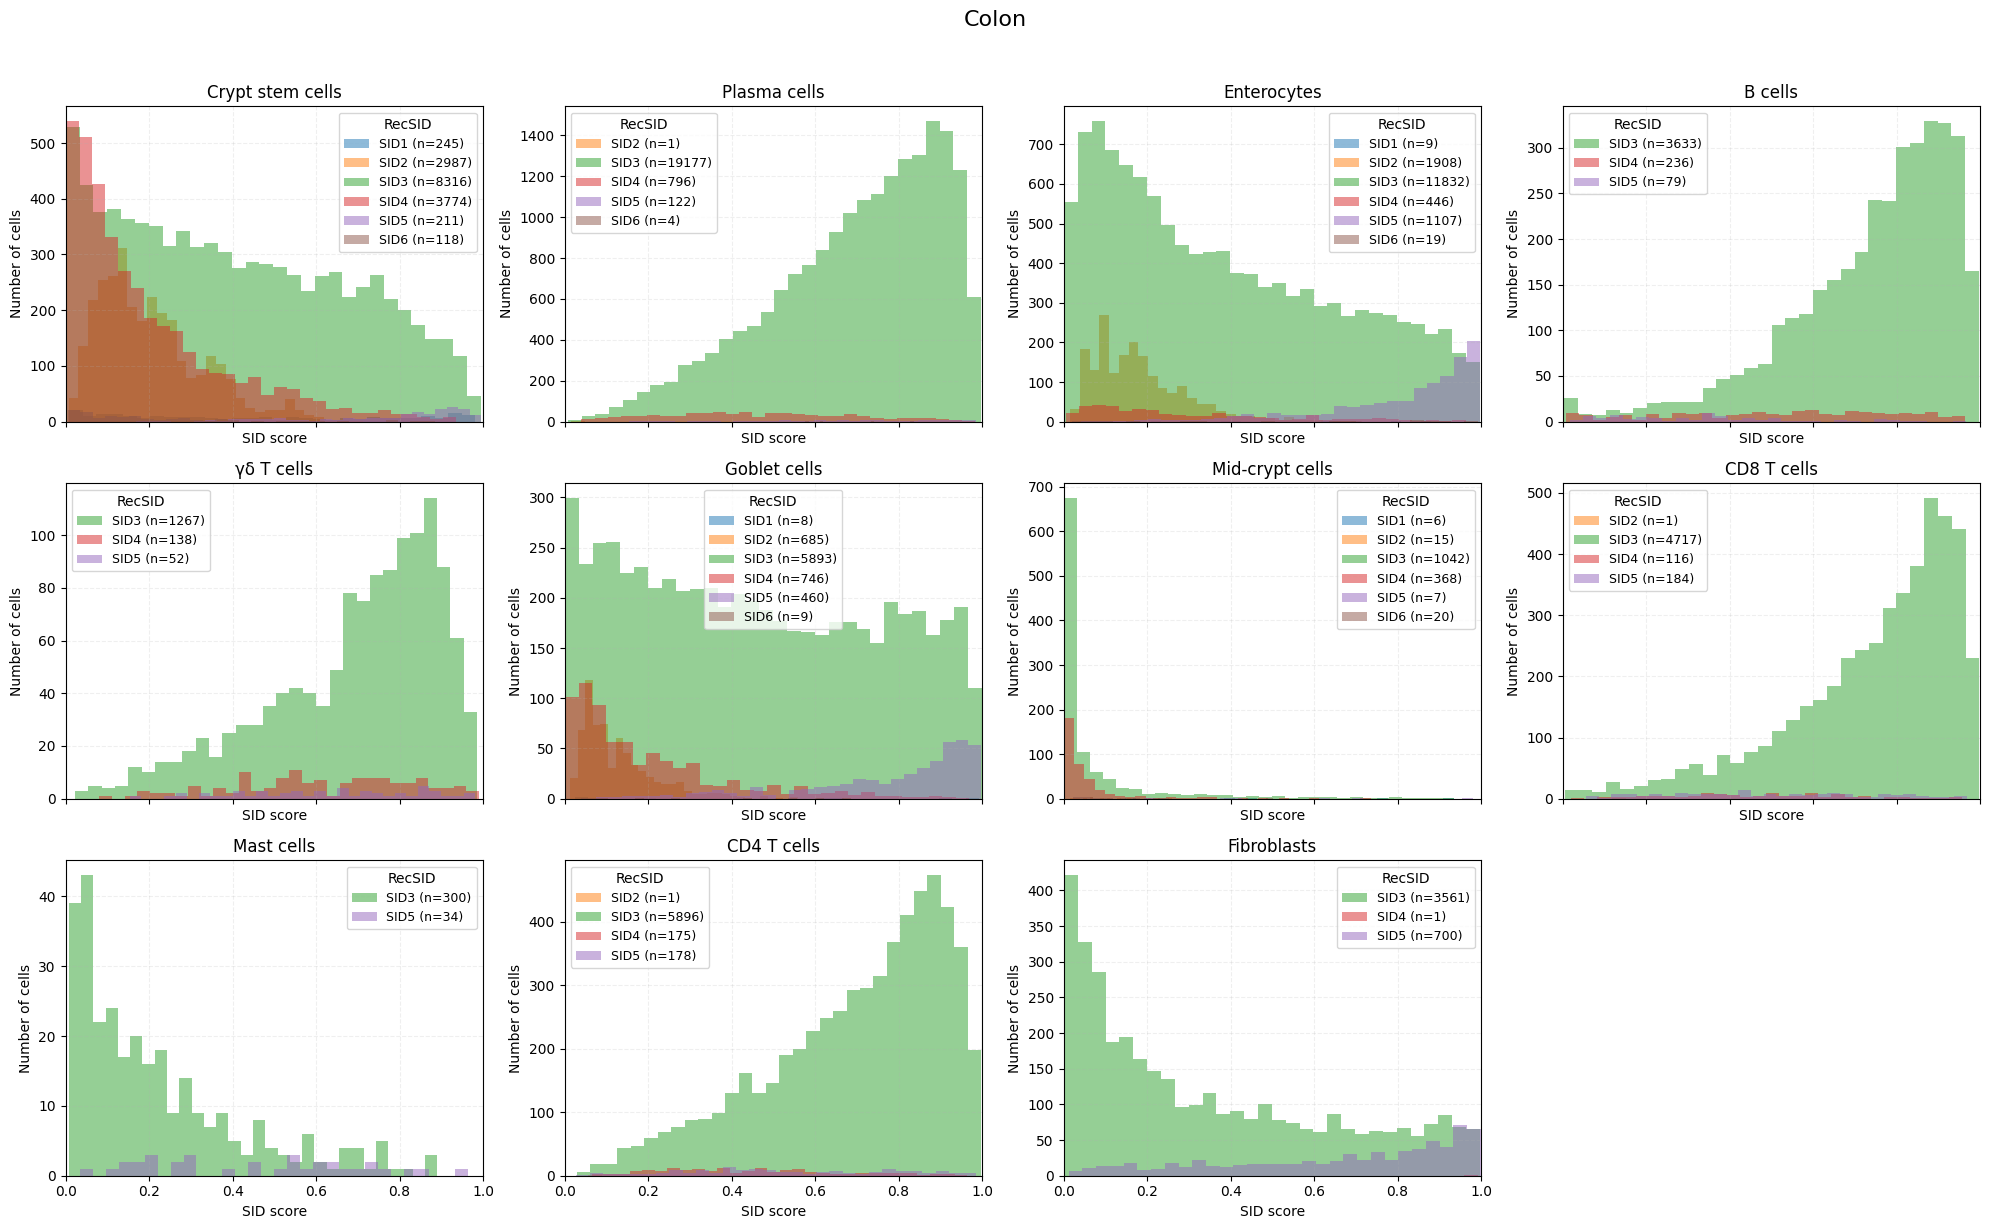

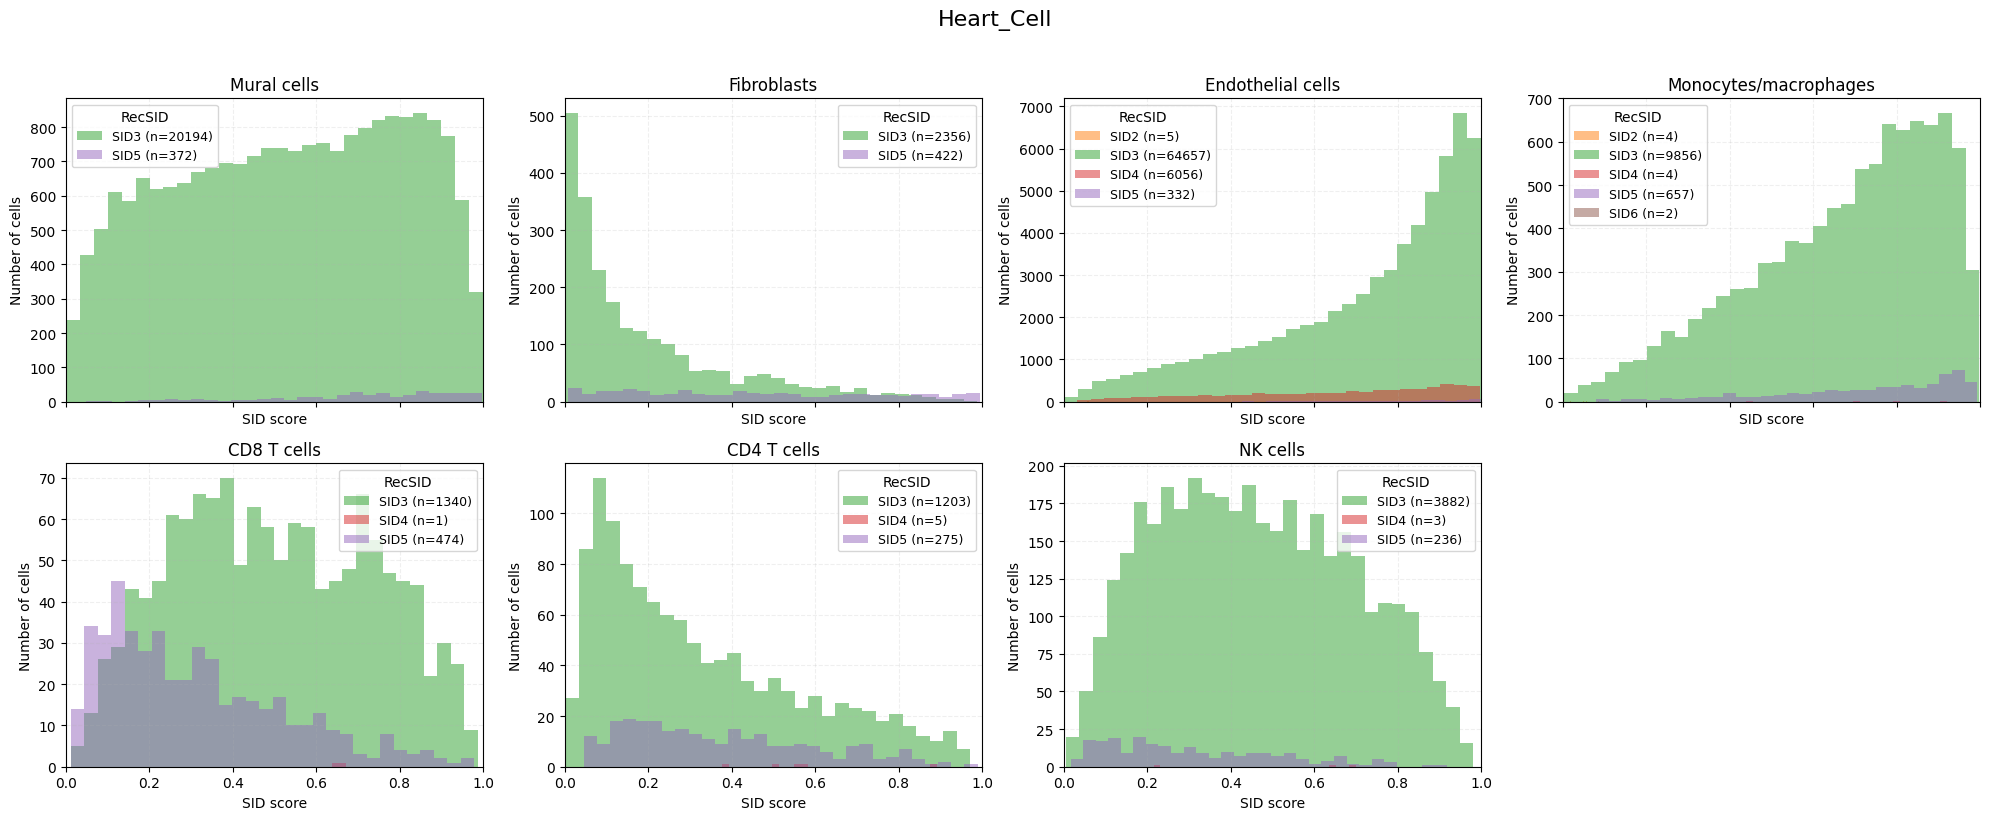

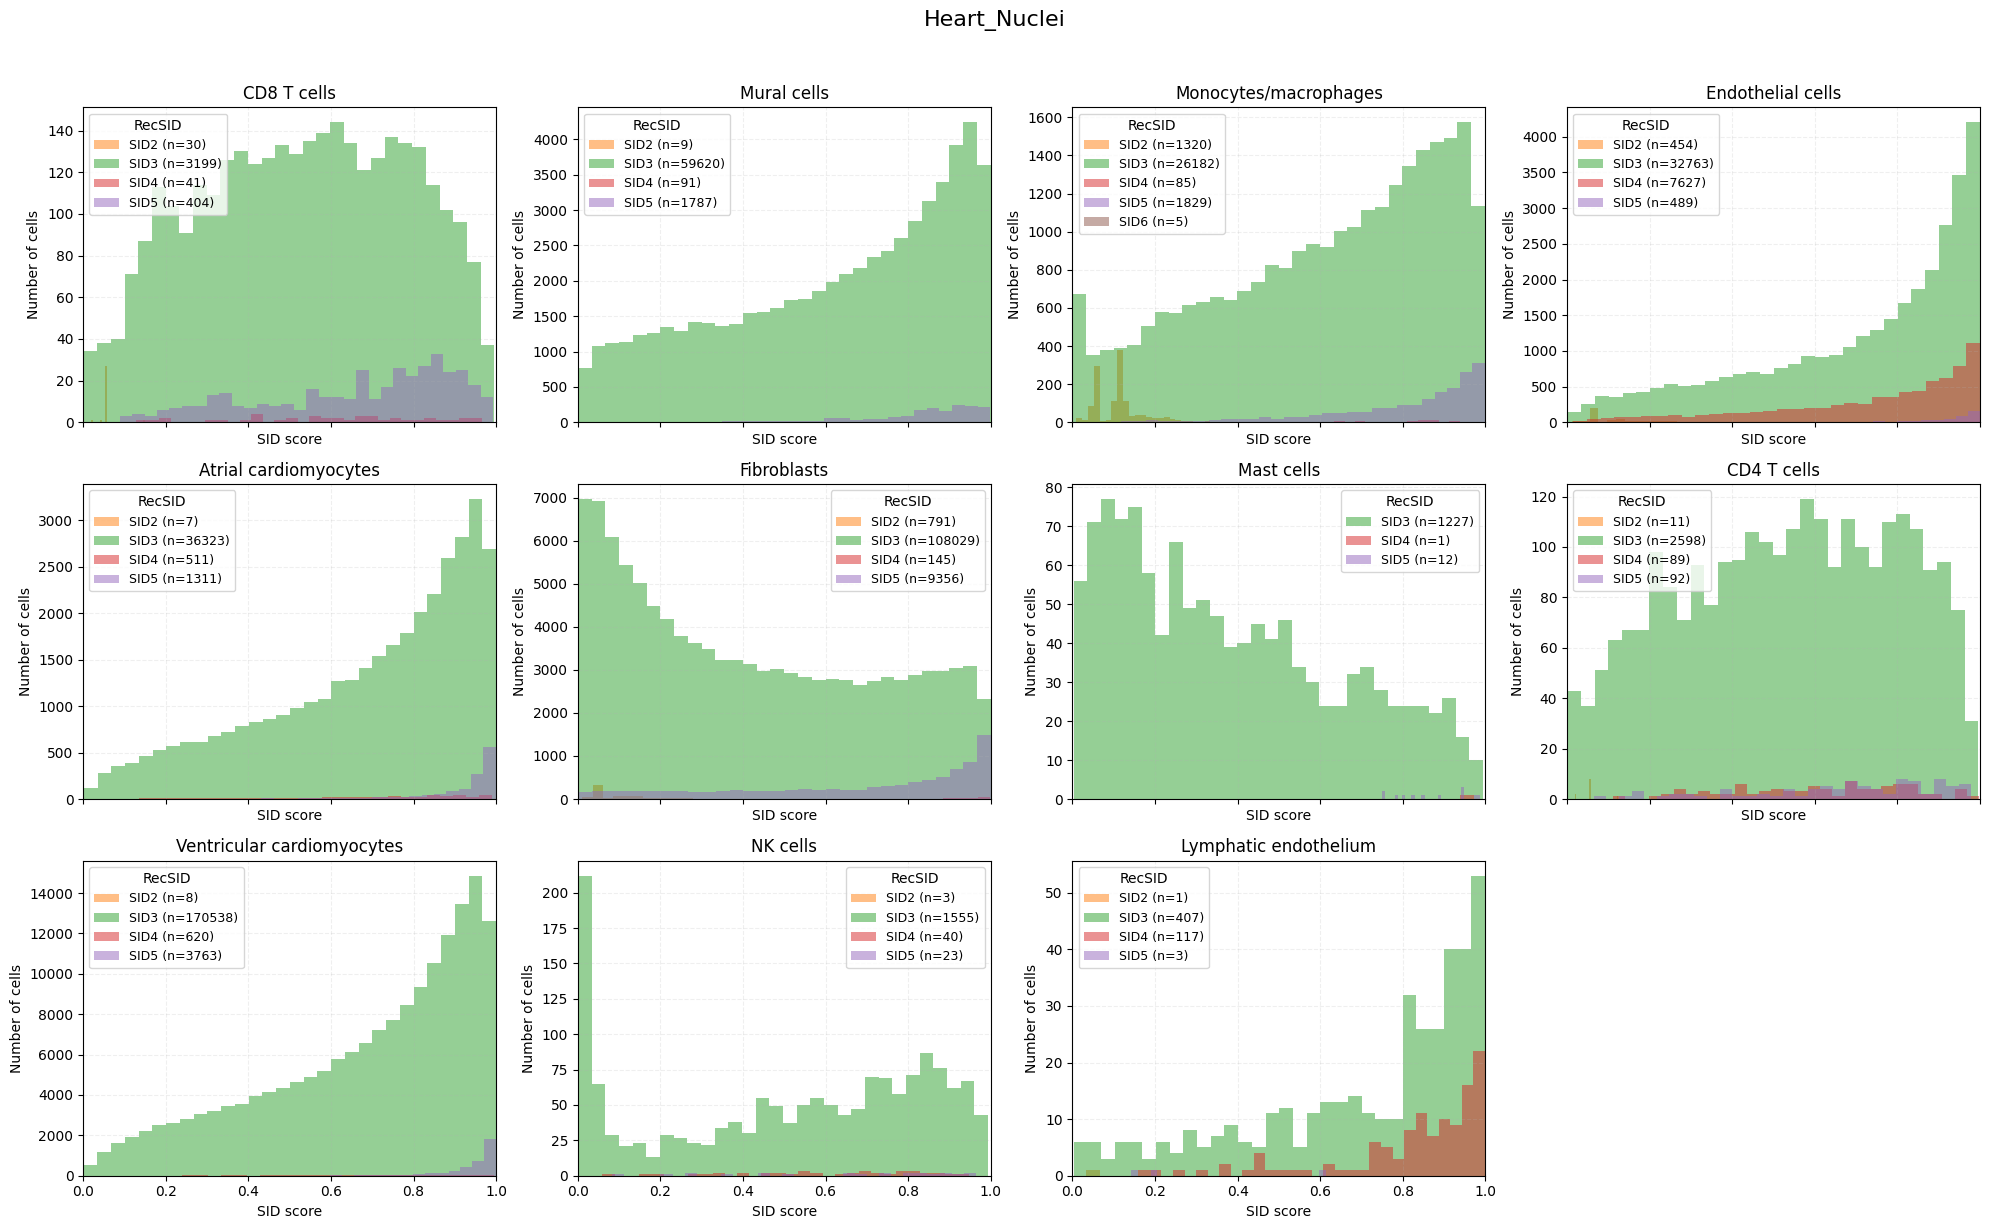

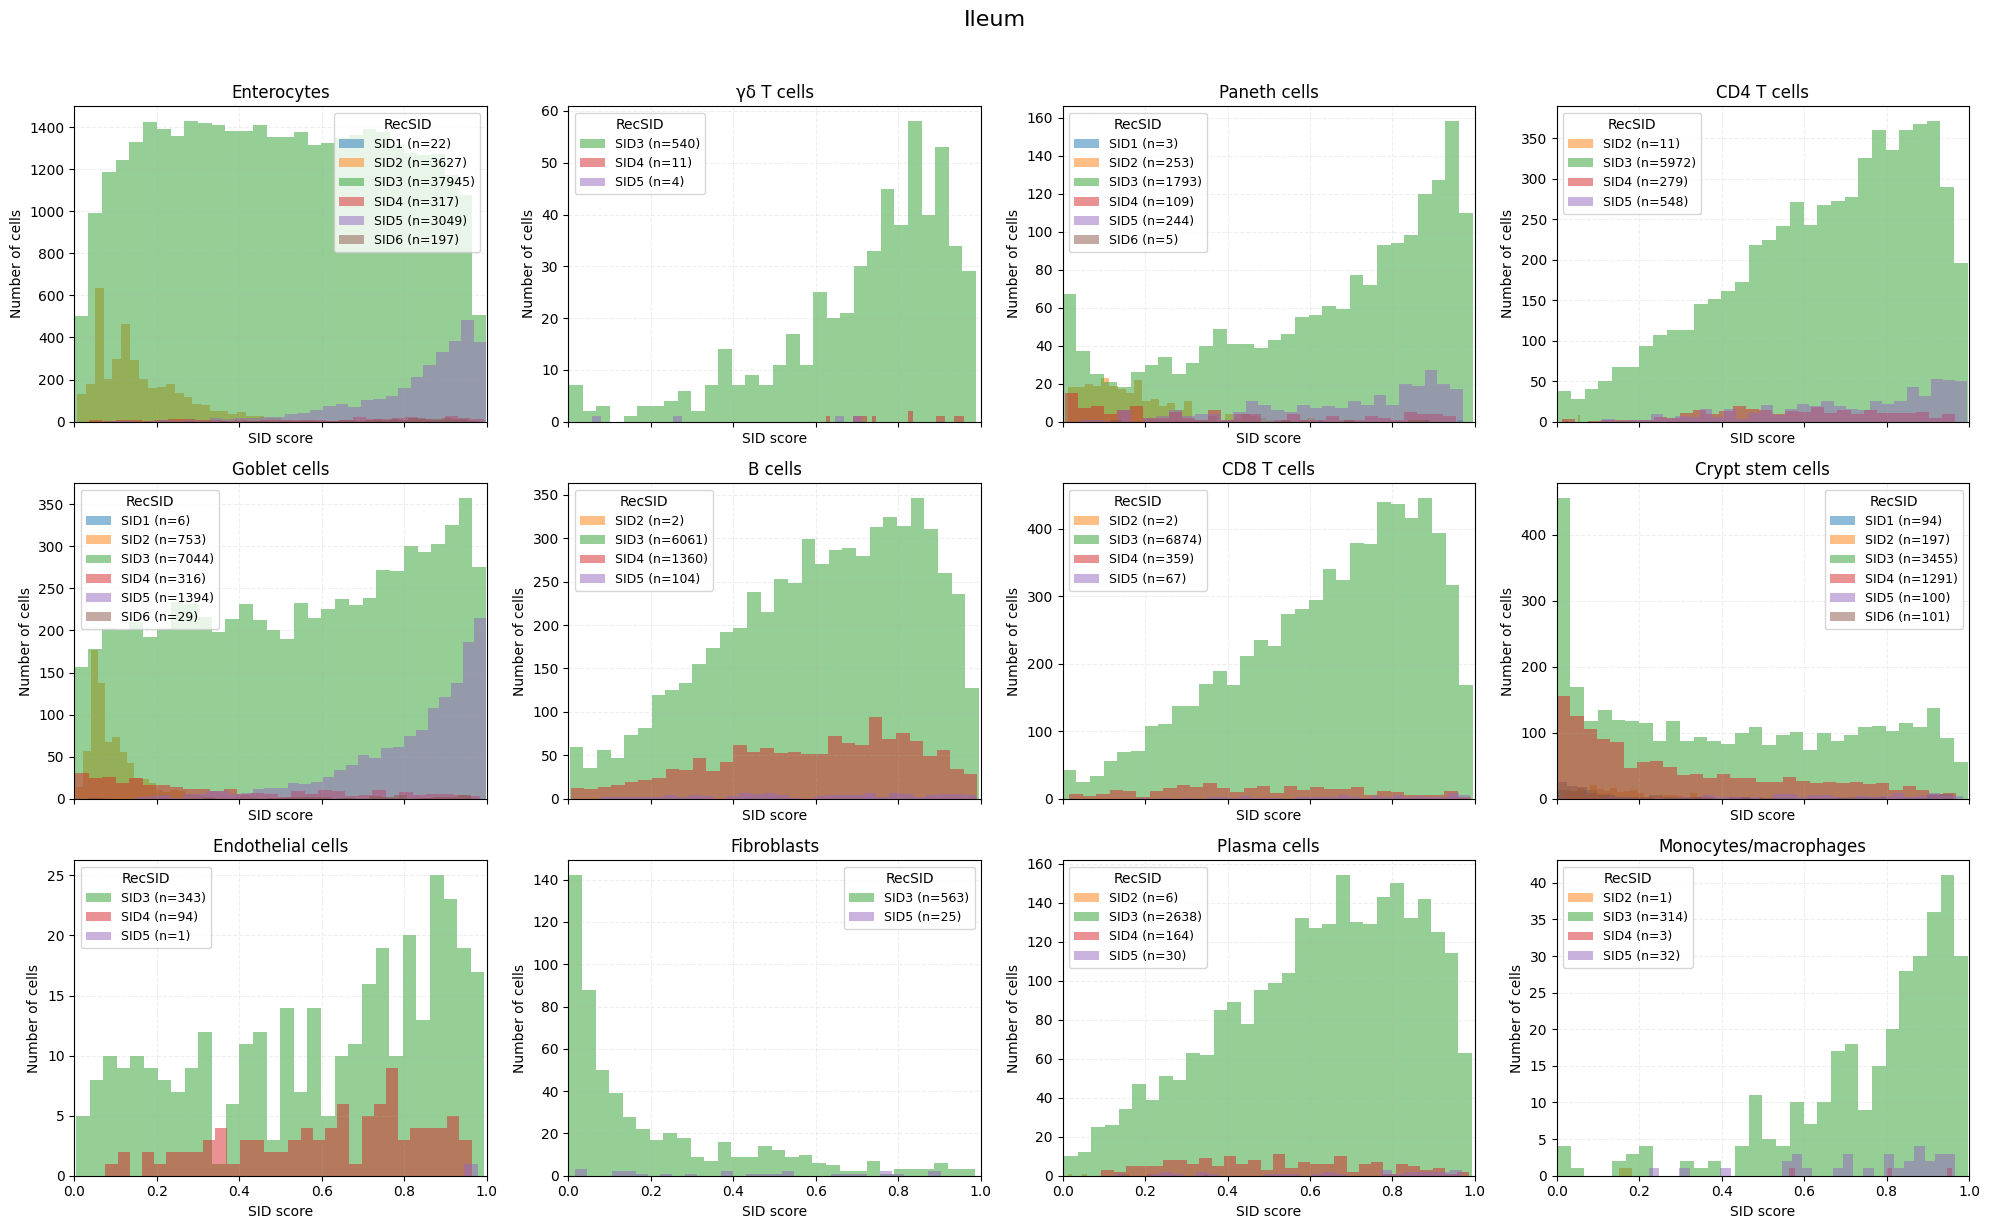

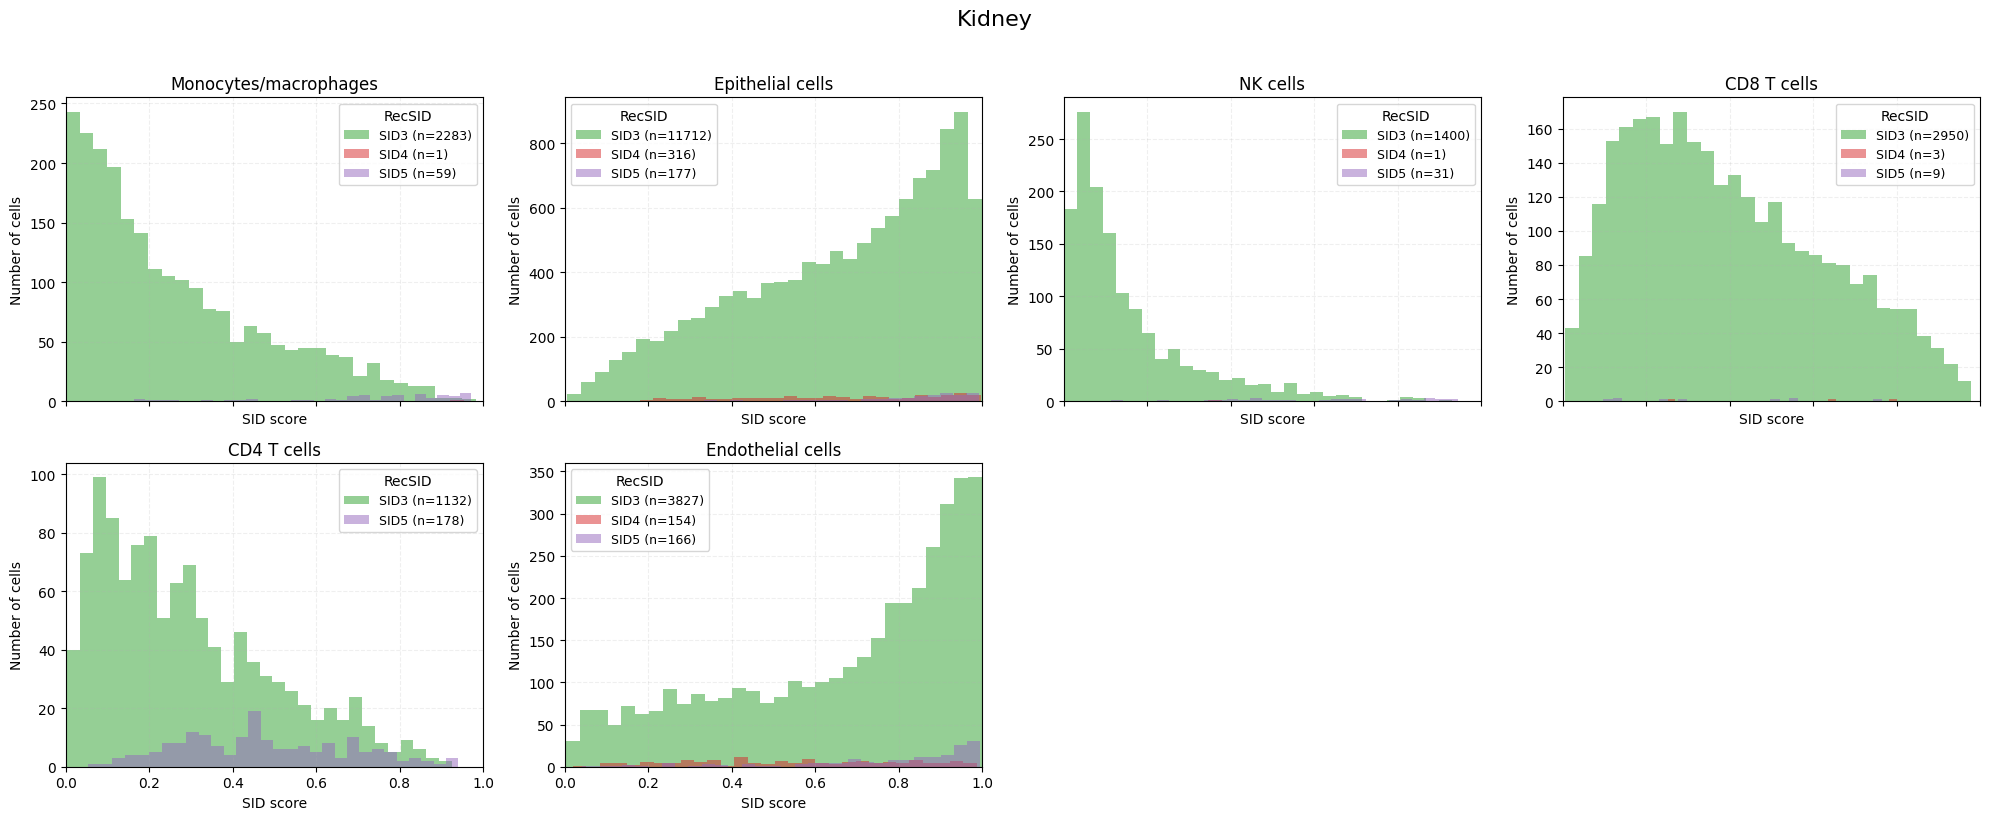

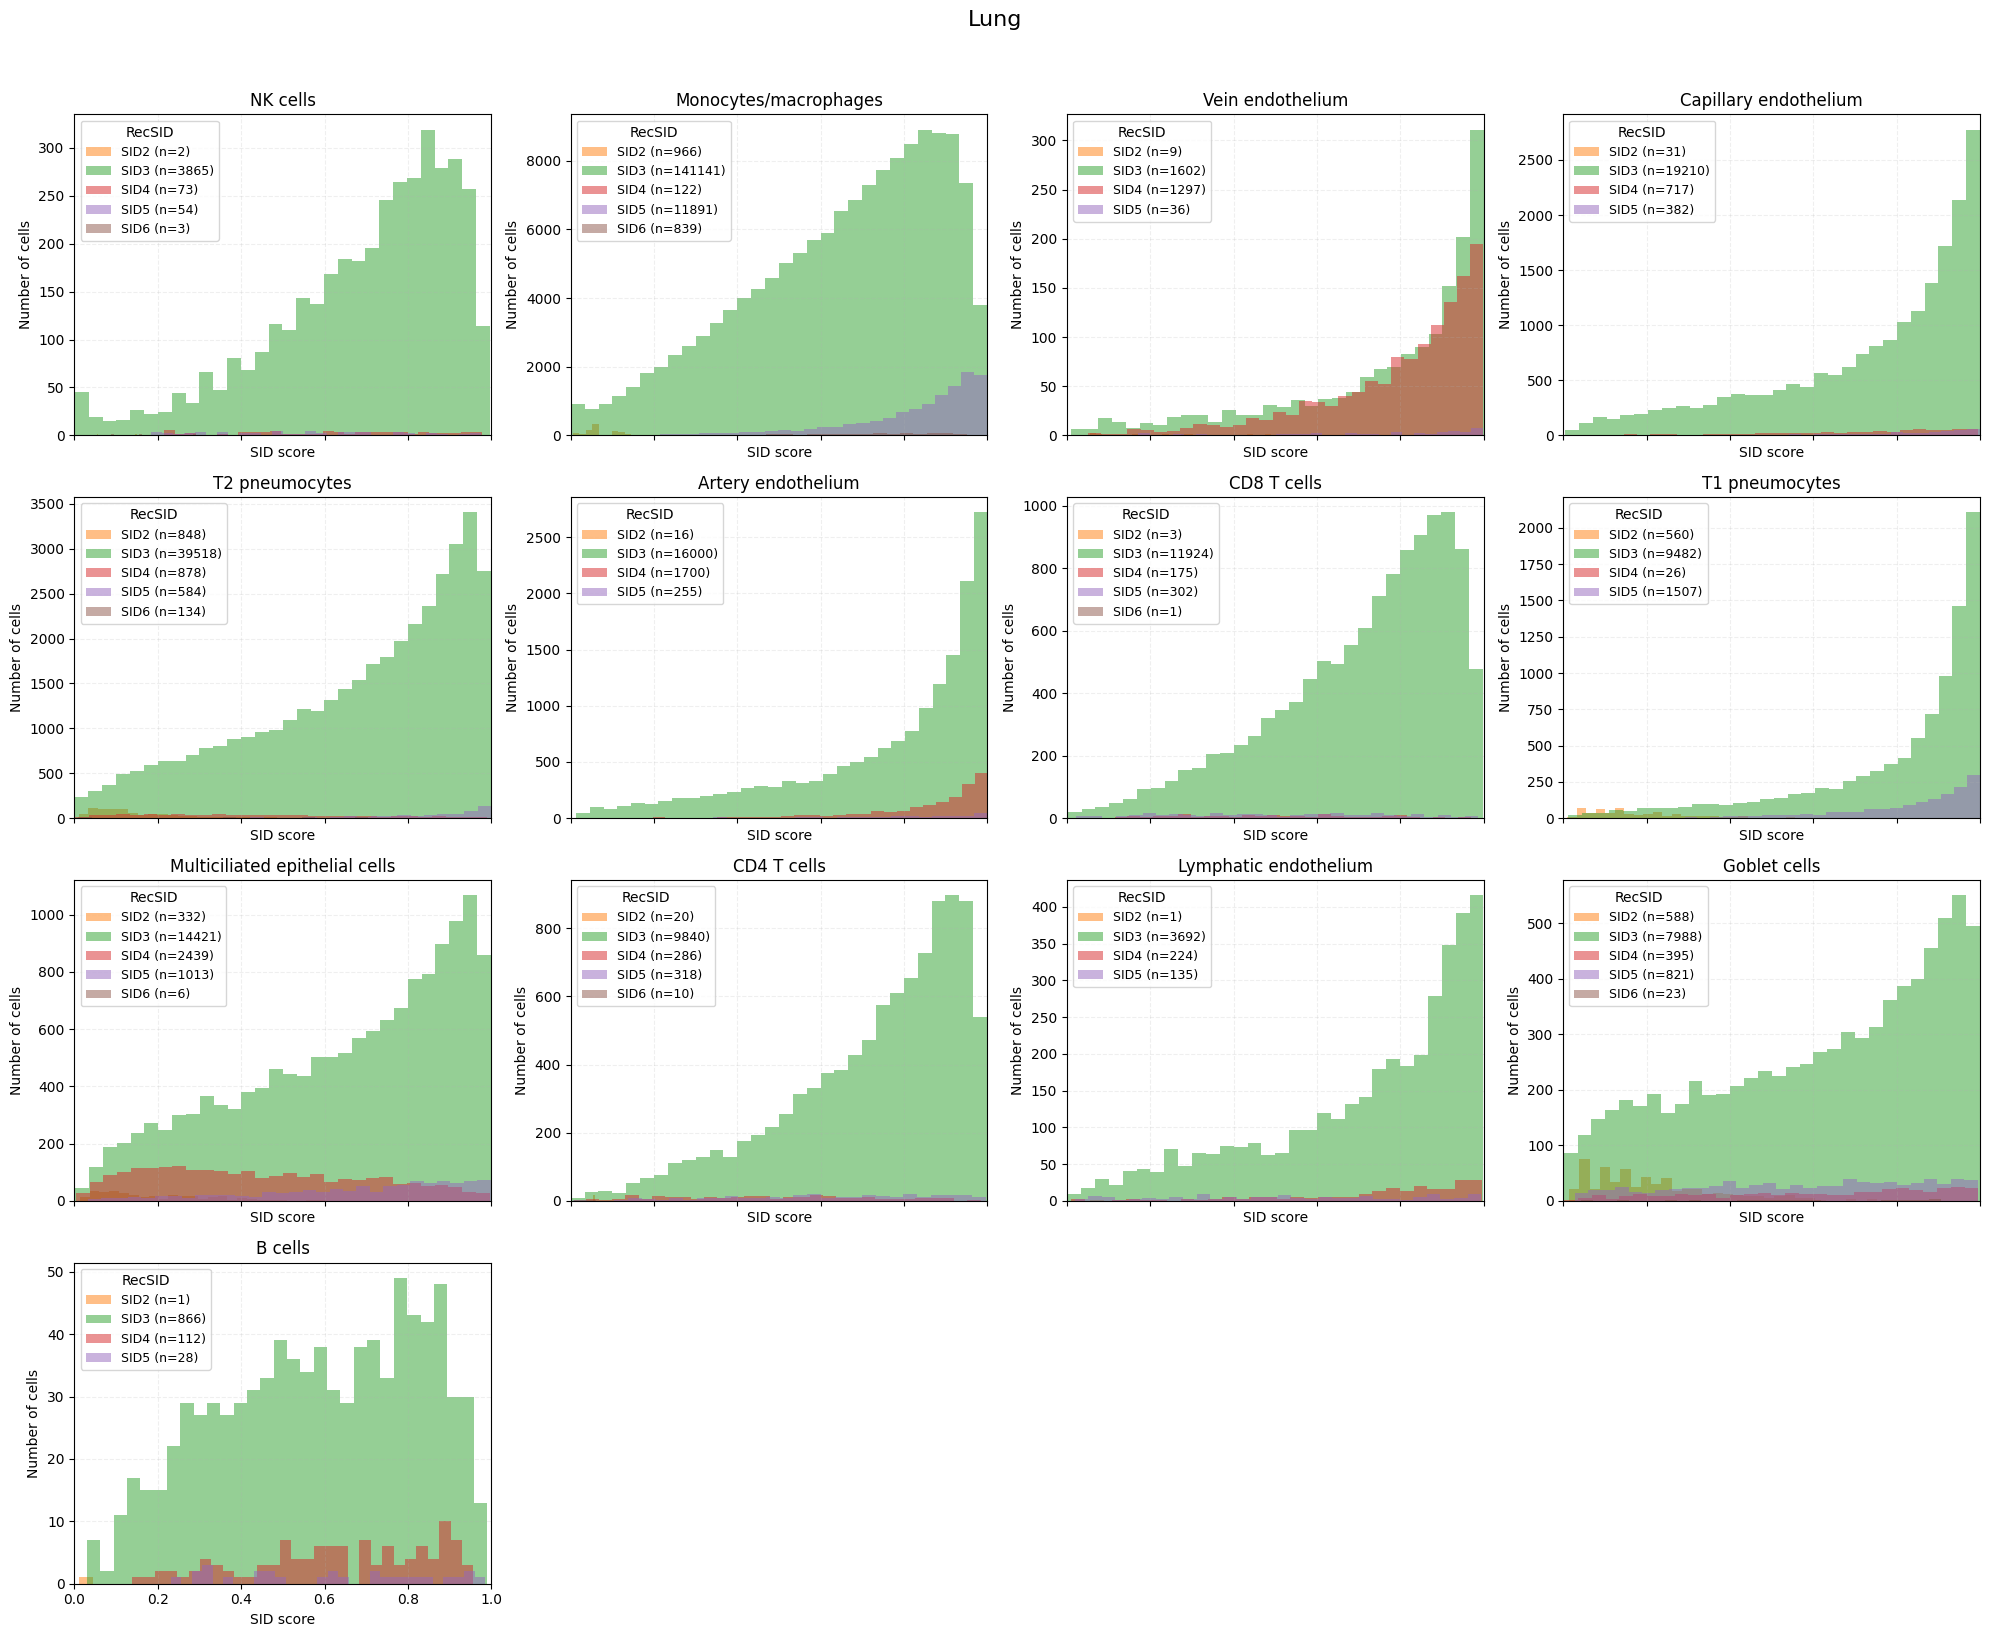

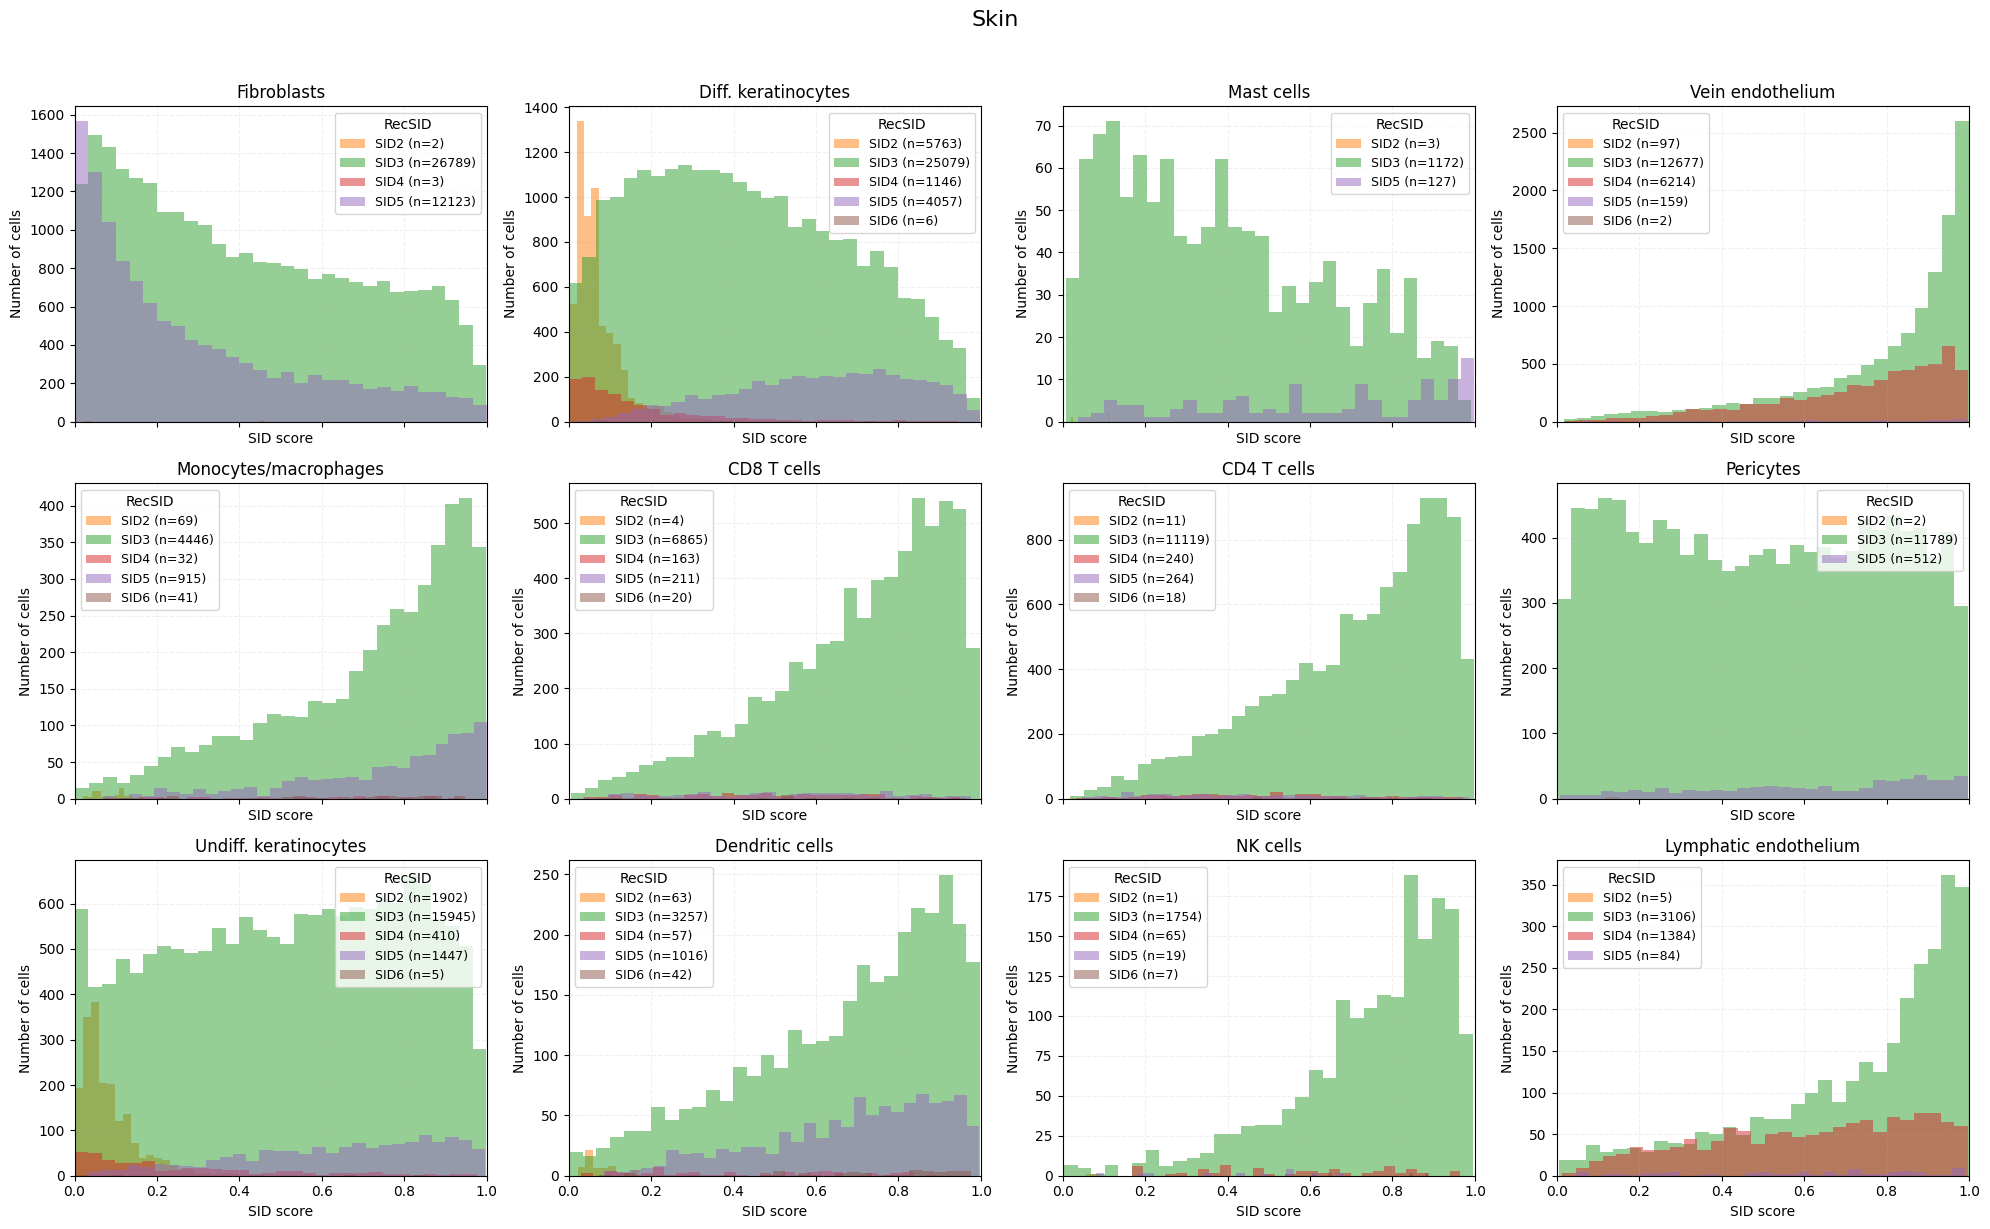

In [ ]:
# Цвета для RecSID
rec_sids = sorted(obs_score["RecSID"].dropna().unique())
palette = dict(zip(rec_sids, sns.color_palette("tab10", n_colors=len(rec_sids))))


# Отдельная фигура для каждой ткани
n_cols = 4
for tissue, tissue_data in obs_score.groupby("Tissue_global", observed=True):
    # Уникальные cell types в данной ткани
    cell_types = tissue_data["cell_type"].dropna().unique()
    n_cell_types = len(cell_types)
    # Количество строк
    n_rows = int(np.ceil(n_cell_types / n_cols))

    # Создаём фигуру
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4 * n_rows),
        sharex=True,
    )

    # Приводим axes к одномерному массиву
    axes = np.atleast_1d(axes).flatten()

    for ax, cell_type in zip(axes, cell_types):
        group = tissue_data[tissue_data["cell_type"] == cell_type]
        # Отдельная гистограмма для каждого RecSID
        for rec_sid, sub in group.groupby("RecSID", observed=True):
            ax.hist(
                sub["sid_score"],
                bins=30,
                alpha=0.5,
                color=palette[rec_sid],
                label=f"{rec_sid} (n={len(sub)})",
            )
        ax.set_xlim(0, 1)
        ax.set_title(cell_type)
        ax.set_xlabel("SID score")
        ax.set_ylabel("Number of cells")
        ax.legend(title="RecSID", fontsize=9)
        ax.grid(alpha=0.2, linestyle="--")

    for ax in axes[n_cell_types:]:
        fig.delaxes(ax)

    fig.suptitle(tissue, fontsize=16, y=1.02)

    plt.tight_layout()
    plt.show()

In [26]:
sp_scores = pd.read_csv(
    ".././sp_2nd_scores_is_sen_labels.csv",
    index_col=0,
)
sp_scores.rename(columns={"sp_score_sigs_dw": "sp_score"}, inplace=True)
sp_scores.head(2)

,sp_score,centered_median,is_sen_GMMk2_median_ct
AAACCTGAGGCCGAAT-1-GSM3758115,3.951097,1.170299,False
AAACCTGAGTTAAGTG-1-GSM3758115,0.114196,-0.033471,False


In [29]:
all_scores = adata.obs.join(
    [sp_scores["sp_score"], sd_scores_rec, ds_scores, auc_scores], how="left"
)
all_scores.rename(columns={"FRIDMAN_SENESCENCE_UP": "fridman"}, inplace=True)
print(all_scores.shape)
all_scores.head(2)

(1253024, 15)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp_score,RecSID,sid_score,ds,fridman,cellage,senmayo
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21.0,Fibroblasts,950.0,3.951097,SID3,0.773698,0.156639,0.222860,0.048563,0.124413
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21.0,CD8 T cells,1247.0,0.114196,SID3,0.607294,0.125290,0.096653,0.047017,0.039243


In [30]:
all_scores.to_csv(".././4_all_sen_scores_obs.csv")